In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


In [3]:
search_roots = [Path("/kaggle/input"), Path.cwd()]
found_files = []
for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.name.lower() in {
                "vehicle_train_10000.csv", "vehicle_test.csv", "test.csv",
                "train.csv", "sample_submission.csv"
            }:
                found_files.append(p)

# Remove duplicates while preserving order
found_files = list(dict.fromkeys(found_files))
print("CSV files found:")
for p in found_files:
    print(p)

def find_file(possible_names, required=True):
    matches = [p for p in found_files if p.name.lower() in {n.lower() for n in possible_names}]
    if not matches:
        if required:
            raise FileNotFoundError(
                f"Could not find any of {possible_names}. Attach the competition dataset via Kaggle's Add Input."
            )
        return None
    # Prefer paths under /kaggle/input over any working-directory copy
    matches.sort(key=lambda p: ("/kaggle/input" not in str(p), len(str(p))))
    return matches[0]

TRAIN_PATH = find_file(["vehicle_train_10000.csv", "train.csv"])
TEST_PATH = find_file(["vehicle_test.csv", "test.csv"])
SAMPLE_PATH = find_file(["sample_submission.csv"], required=False)

print("\nSelected training file:", TRAIN_PATH)
print("Selected test file:", TEST_PATH)
print("Selected sample submission:", SAMPLE_PATH)

CSV files found:
/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv

Selected training file: /kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
Selected test file: /kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
Selected sample submission: None


In [4]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH) if SAMPLE_PATH is not None else None

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
print("\nTraining preview:")
display(train_df.head())
print("\nTest preview:")
display(test_df.head())

TARGET = "vehicle_class"
if TARGET not in train_df.columns:
    raise ValueError(f"Expected target column '{TARGET}' in training data.")
print("\nTarget exists in train:", TARGET in train_df.columns)
print("Target exists in test:", TARGET in test_df.columns)

Train shape: (10000, 22)
Test shape: (2500, 21)
Train columns: ['vehicle_id', 'engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh', 'vehicle_class']
Test columns: ['vehicle_id', 'engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh']

Training 

,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1



Test preview:


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh
0,10001,2.17,279.0,1632.0,2752.0,4625.0,1805.0,1695.0,59.0,12.47,17.40,6.0,355.0,183.0,5.98,576.0,8.63,41.0,234.0,0.31,65.0
1,10002,1.61,189.0,1387.0,2618.0,4440.0,1766.0,1410.0,46.0,14.13,18.19,5.0,267.0,113.0,4.72,244.0,8.73,36.0,187.0,0.27,66.0
2,10003,3.00,375.0,2035.0,2990.0,5185.0,2016.0,1614.0,83.0,8.77,13.52,7.0,505.0,206.0,6.22,683.0,6.06,52.0,295.0,0.37,70.0
3,10004,2.45,316.0,1169.0,2543.0,4272.0,1698.0,1338.0,35.0,13.29,15.67,6.0,451.0,110.0,5.74,212.0,5.05,29.0,254.0,0.27,79.0
4,10005,3.08,321.0,2262.0,3063.0,5358.0,2050.0,1509.0,83.0,8.69,13.75,6.0,481.0,149.0,6.48,586.0,6.94,55.0,306.0,0.37,59.0



Target exists in train: True
Target exists in test: False


In [5]:
print("Training data info:")
train_df.info()

quality = pd.DataFrame({
    "dtype": train_df.dtypes.astype(str),
    "missing_count": train_df.isna().sum(),
    "missing_percent": (train_df.isna().mean() * 100).round(2),
    "unique_values": train_df.nunique(dropna=False)
})
display(quality)

print("Exact duplicate rows in train:", train_df.duplicated().sum())
print("Exact duplicate rows in test:", test_df.duplicated().sum())
print("Duplicate vehicle_id values in train:", train_df["vehicle_id"].duplicated().sum() if "vehicle_id" in train_df else "no vehicle_id")
print("Duplicate vehicle_id values in test:", test_df["vehicle_id"].duplicated().sum() if "vehicle_id" in test_df else "no vehicle_id")

Training data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   vehicle_id                    10000 non-null  int64  
 1   engine_displacement_l         10000 non-null  float64
 2   horsepower_hp                 10000 non-null  float64
 3   vehicle_weight_kg             10000 non-null  float64
 4   wheelbase_mm                  10000 non-null  float64
 5   vehicle_length_mm             10000 non-null  float64
 6   vehicle_width_mm              10000 non-null  float64
 7   vehicle_height_mm             10000 non-null  float64
 8   fuel_tank_capacity_l          10000 non-null  float64
 9   city_fuel_efficiency_kmpl     10000 non-null  float64
 10  highway_fuel_efficiency_kmpl  10000 non-null  float64
 11  engine_cylinders              10000 non-null  float64
 12  torque_nm                     10000 non-n

,dtype,missing_count,missing_percent,unique_values
vehicle_id,int64,0,0.0,10000
engine_displacement_l,float64,0,0.0,329
horsepower_hp,float64,0,0.0,451
vehicle_weight_kg,float64,0,0.0,1271
wheelbase_mm,float64,0,0.0,806
vehicle_length_mm,float64,0,0.0,1418
vehicle_width_mm,float64,0,0.0,401
vehicle_height_mm,float64,0,0.0,663
fuel_tank_capacity_l,float64,0,0.0,56
city_fuel_efficiency_kmpl,float64,0,0.0,1083


Exact duplicate rows in train: 0
Exact duplicate rows in test: 0
Duplicate vehicle_id values in train: 0
Duplicate vehicle_id values in test: 0


In [6]:
# Validate that test has the same feature columns (excluding the target).
feature_columns = [c for c in train_df.columns if c not in [TARGET, "vehicle_id"]]
missing_test_features = [c for c in feature_columns if c not in test_df.columns]
if missing_test_features:
    raise ValueError(f"Test data is missing expected features: {missing_test_features}")

X = train_df[feature_columns].copy()
y = train_df[TARGET].copy()
X_test = test_df[feature_columns].copy()

print("Number of features:", len(feature_columns))
print("Features:", feature_columns)
print("Target classes:", sorted(y.dropna().unique().tolist()))
print("Missing values in X:", int(X.isna().sum().sum()))
print("Missing values in X_test:", int(X_test.isna().sum().sum()))

Number of features: 20
Features: ['engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh']
Target classes: [0, 1, 2]
Missing values in X: 0
Missing values in X_test: 0


In [7]:
# Validate that test has the same feature columns (excluding the target).
feature_columns = [c for c in train_df.columns if c not in [TARGET, "vehicle_id"]]
missing_test_features = [c for c in feature_columns if c not in test_df.columns]
if missing_test_features:
    raise ValueError(f"Test data is missing expected features: {missing_test_features}")

X = train_df[feature_columns].copy()
y = train_df[TARGET].copy()
X_test = test_df[feature_columns].copy()

print("Number of features:", len(feature_columns))
print("Features:", feature_columns)
print("Target classes:", sorted(y.dropna().unique().tolist()))
print("Missing values in X:", int(X.isna().sum().sum()))
print("Missing values in X_test:", int(X_test.isna().sum().sum()))

Number of features: 20
Features: ['engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh']
Target classes: [0, 1, 2]
Missing values in X: 0
Missing values in X_test: 0


,count,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,2.425913,0.614435,0.90,2.0000,2.43,2.85,4.44
horsepower_hp,10000.0,296.495000,95.563811,90.00,226.0000,294.00,364.00,550.00
vehicle_weight_kg,10000.0,1636.399900,306.182383,1100.00,1409.0000,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.057600,172.346621,2400.00,2651.0000,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.038600,366.060305,3900.00,4387.7500,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.671100,117.744583,1650.00,1744.0000,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.945000,145.978909,1250.00,1423.0000,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,61.096000,14.511383,35.00,50.0000,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.612495,2.565865,7.00,9.7500,11.56,13.36,20.87
highway_fuel_efficiency_kmpl,10000.0,15.851152,2.501685,9.00,14.1600,15.83,17.55,24.07


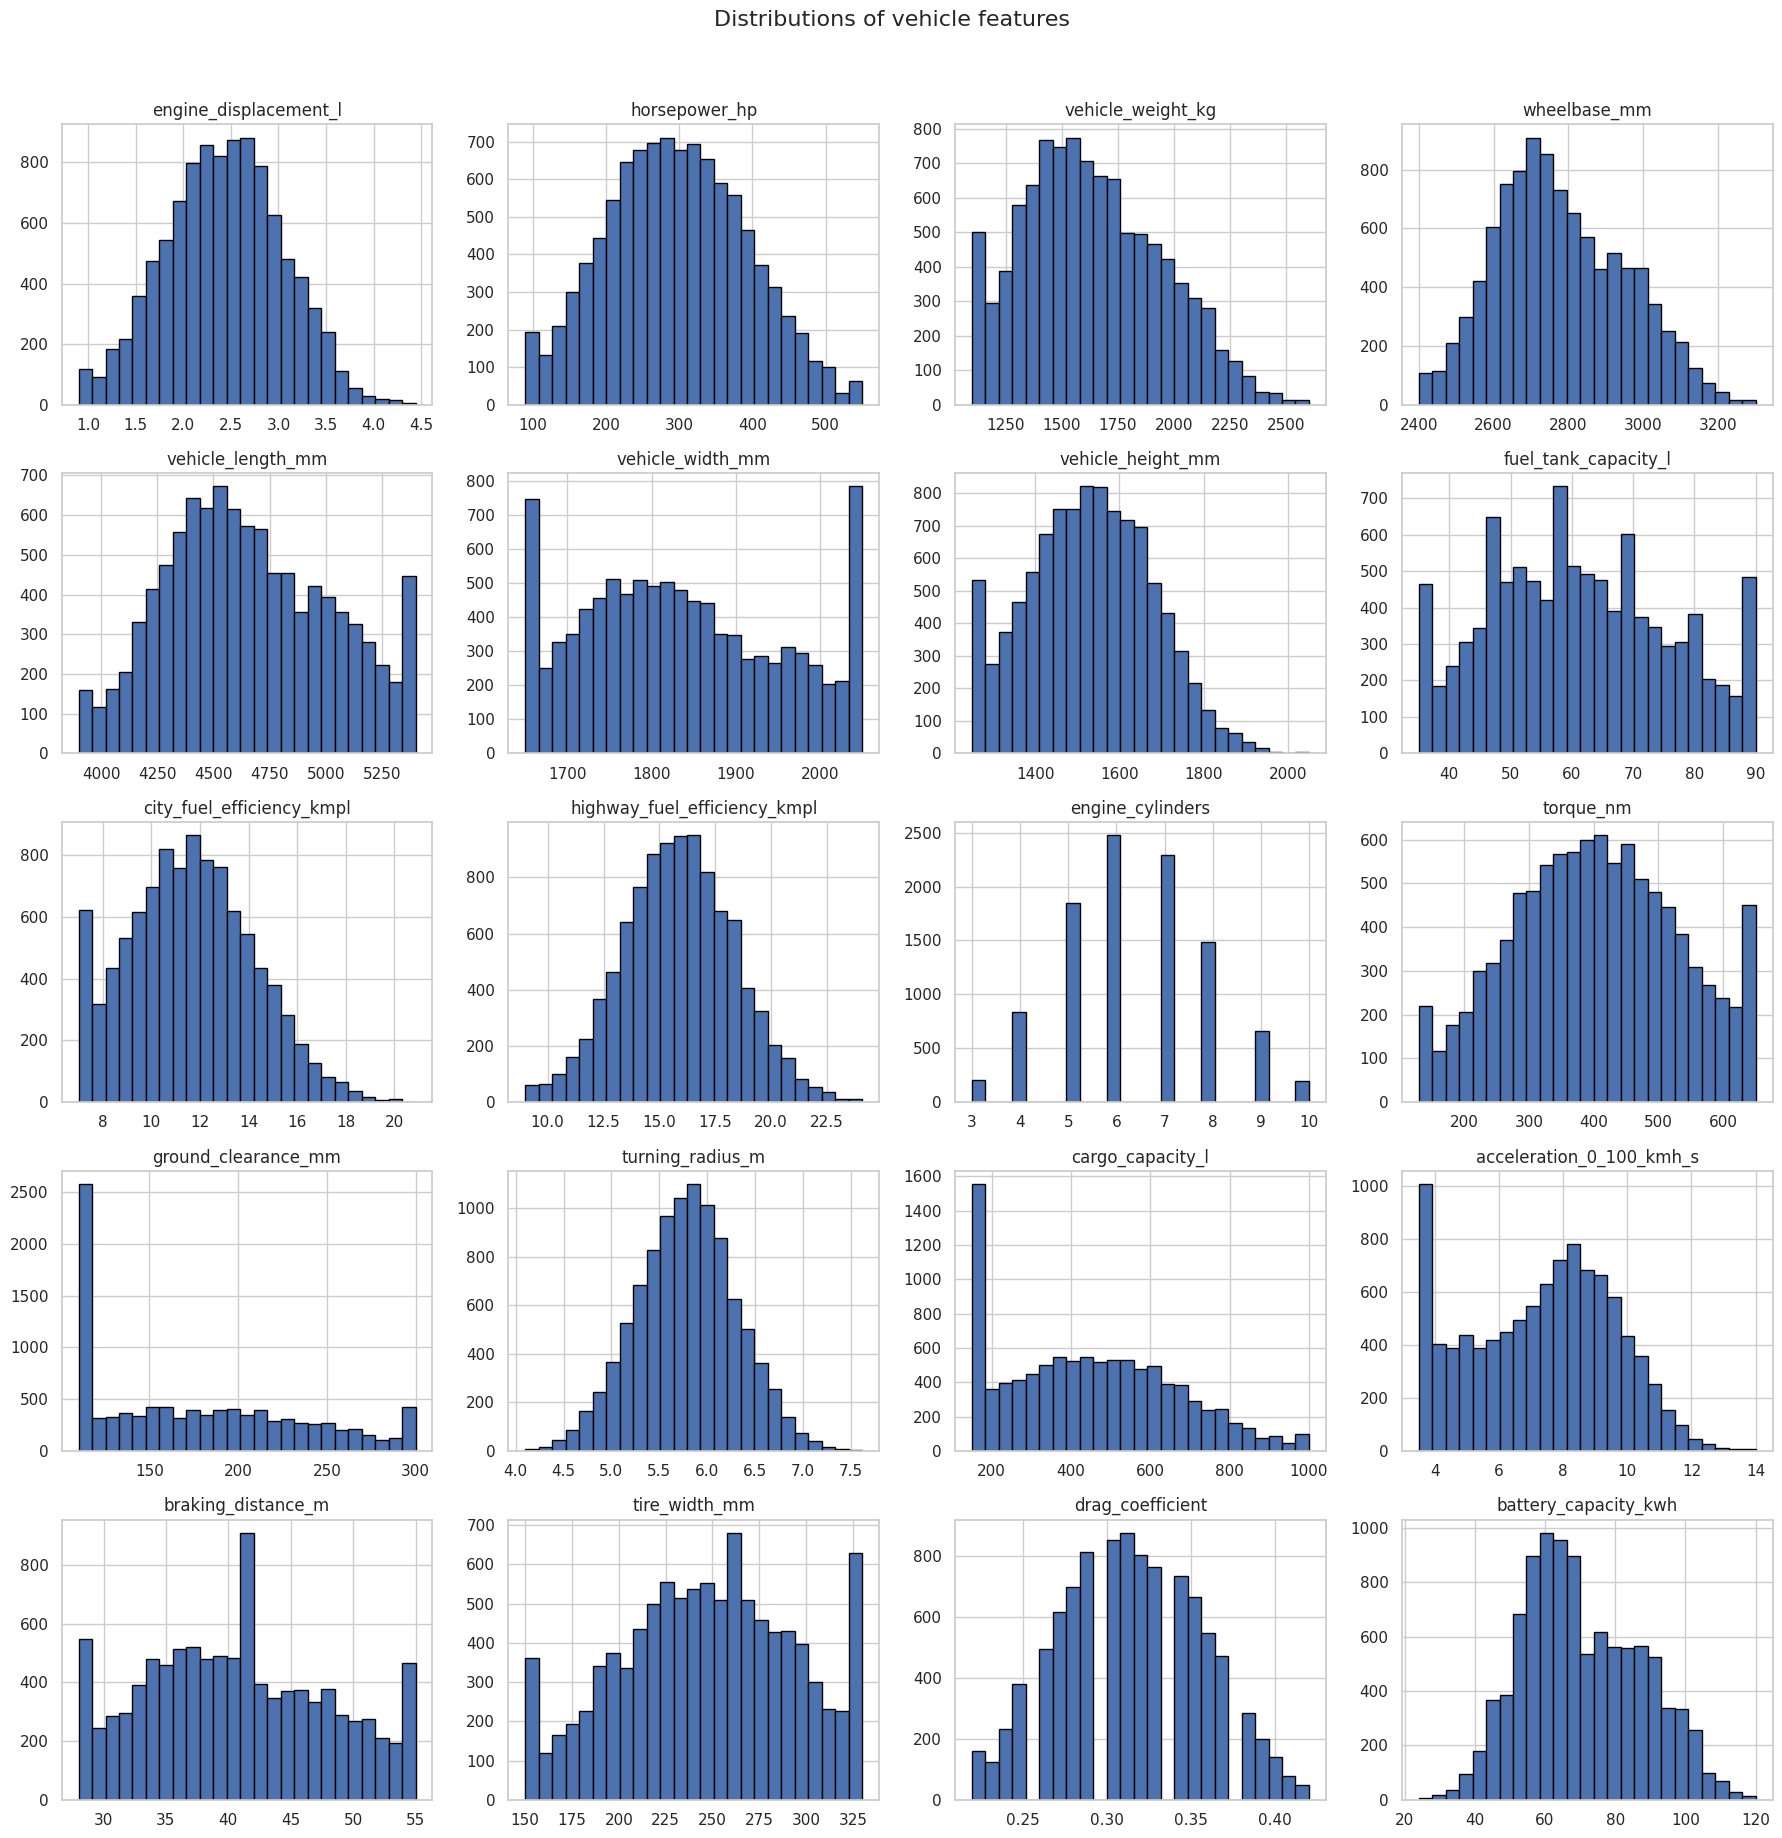

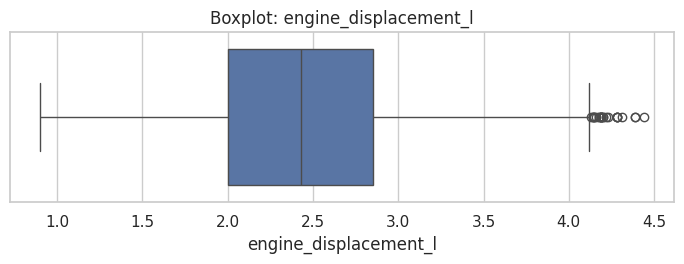

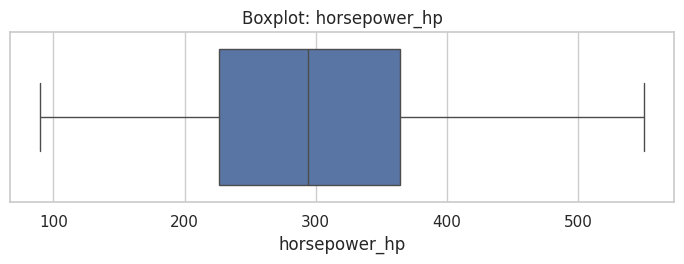

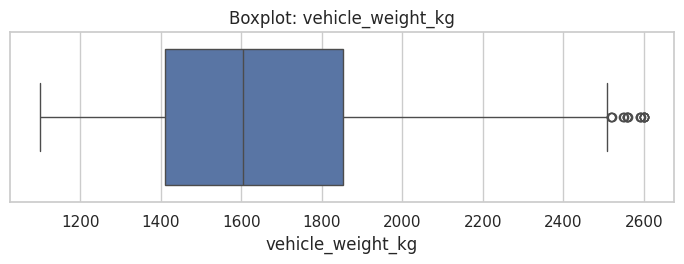

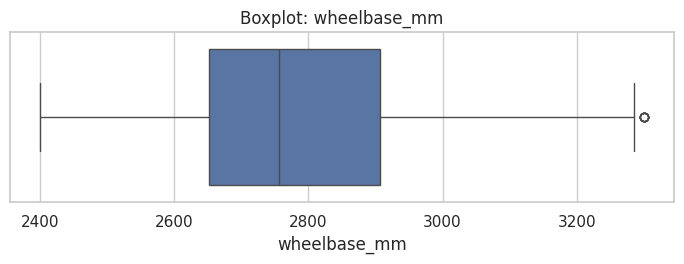

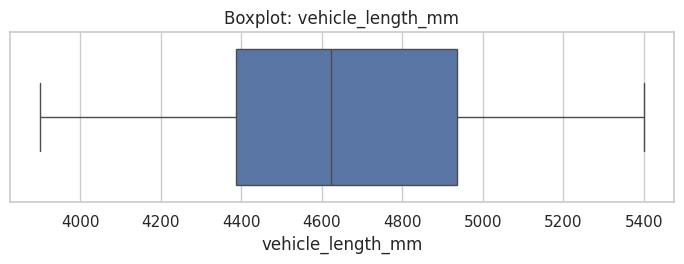

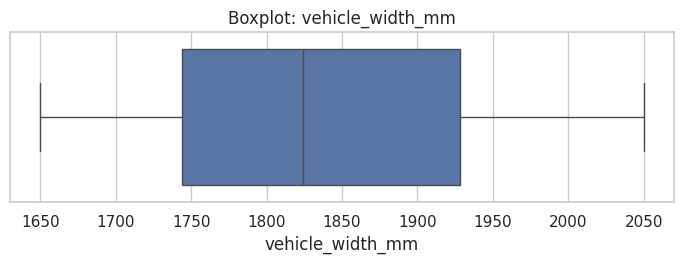

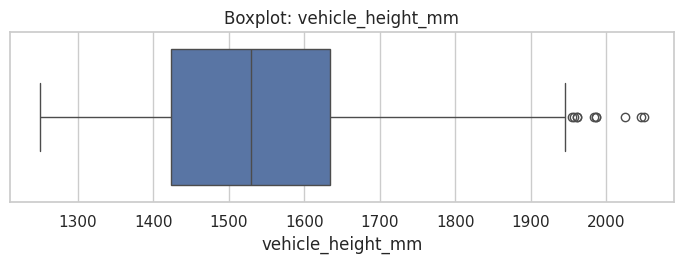

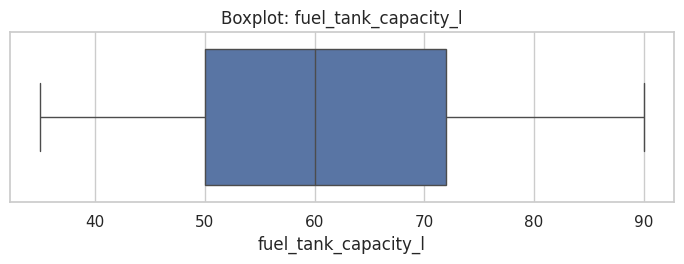

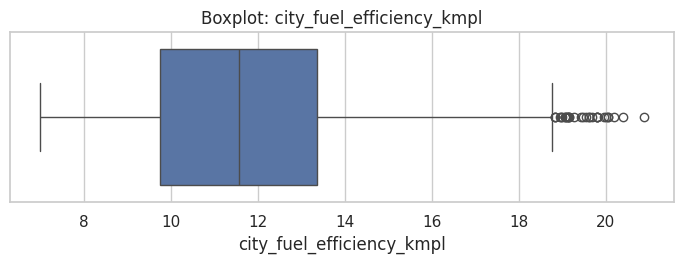

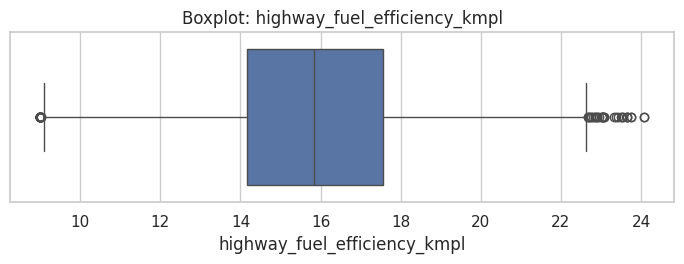

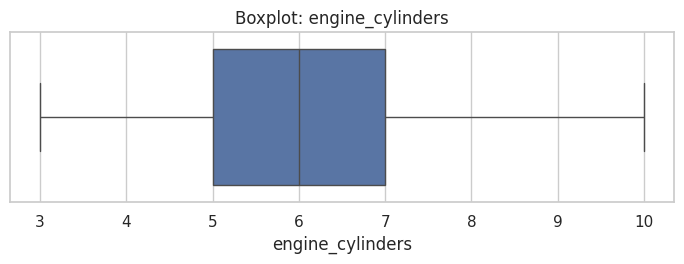

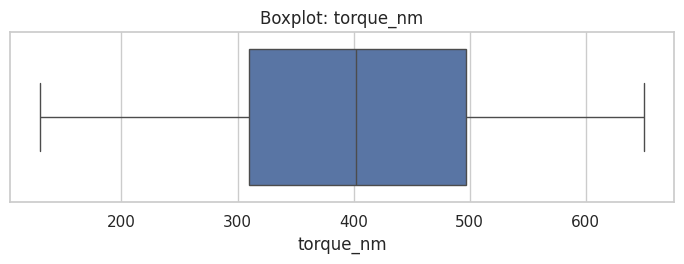

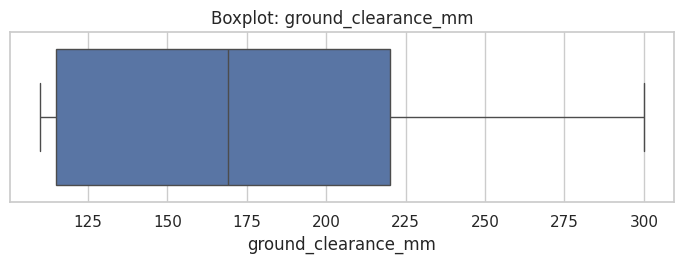

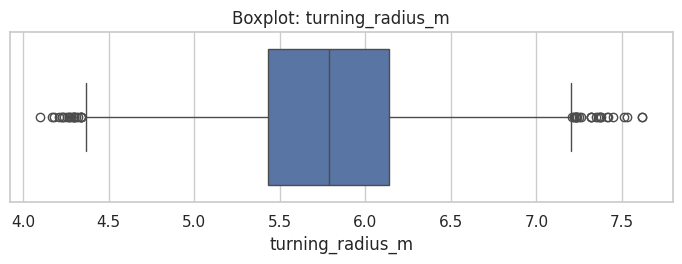

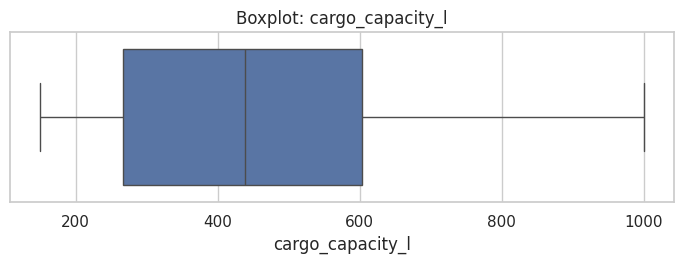

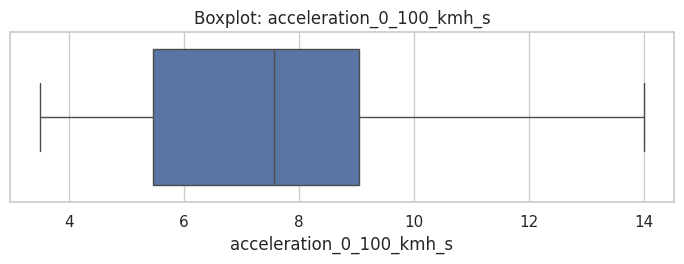

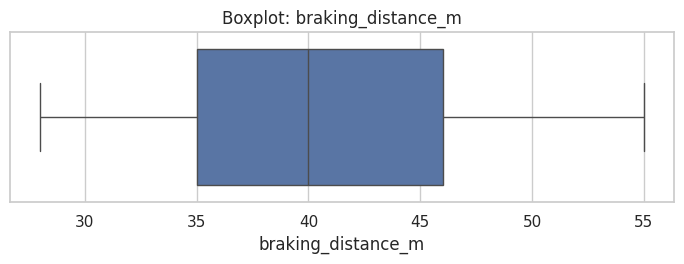

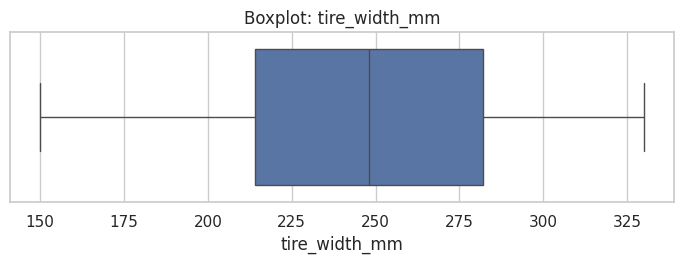

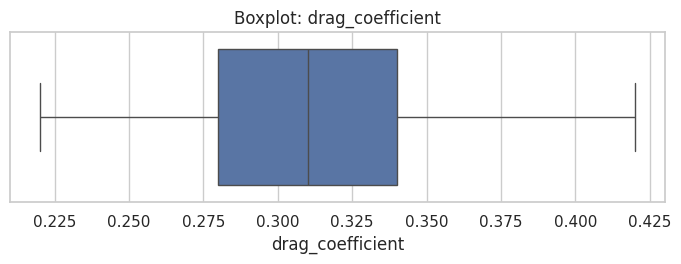

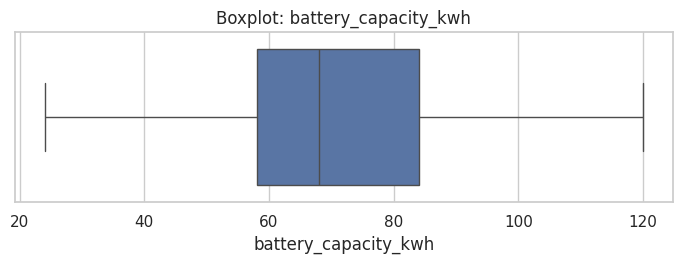

In [8]:
display(train_df[feature_columns].describe().T)

# Histograms help identify skew and unusual ranges.
train_df[feature_columns].hist(figsize=(18, 18), bins=25, edgecolor="black")
plt.suptitle("Distributions of vehicle features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

for feature in feature_columns:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=train_df[feature])
    plt.title(f"Boxplot: {feature}")
    plt.tight_layout()
    plt.show()

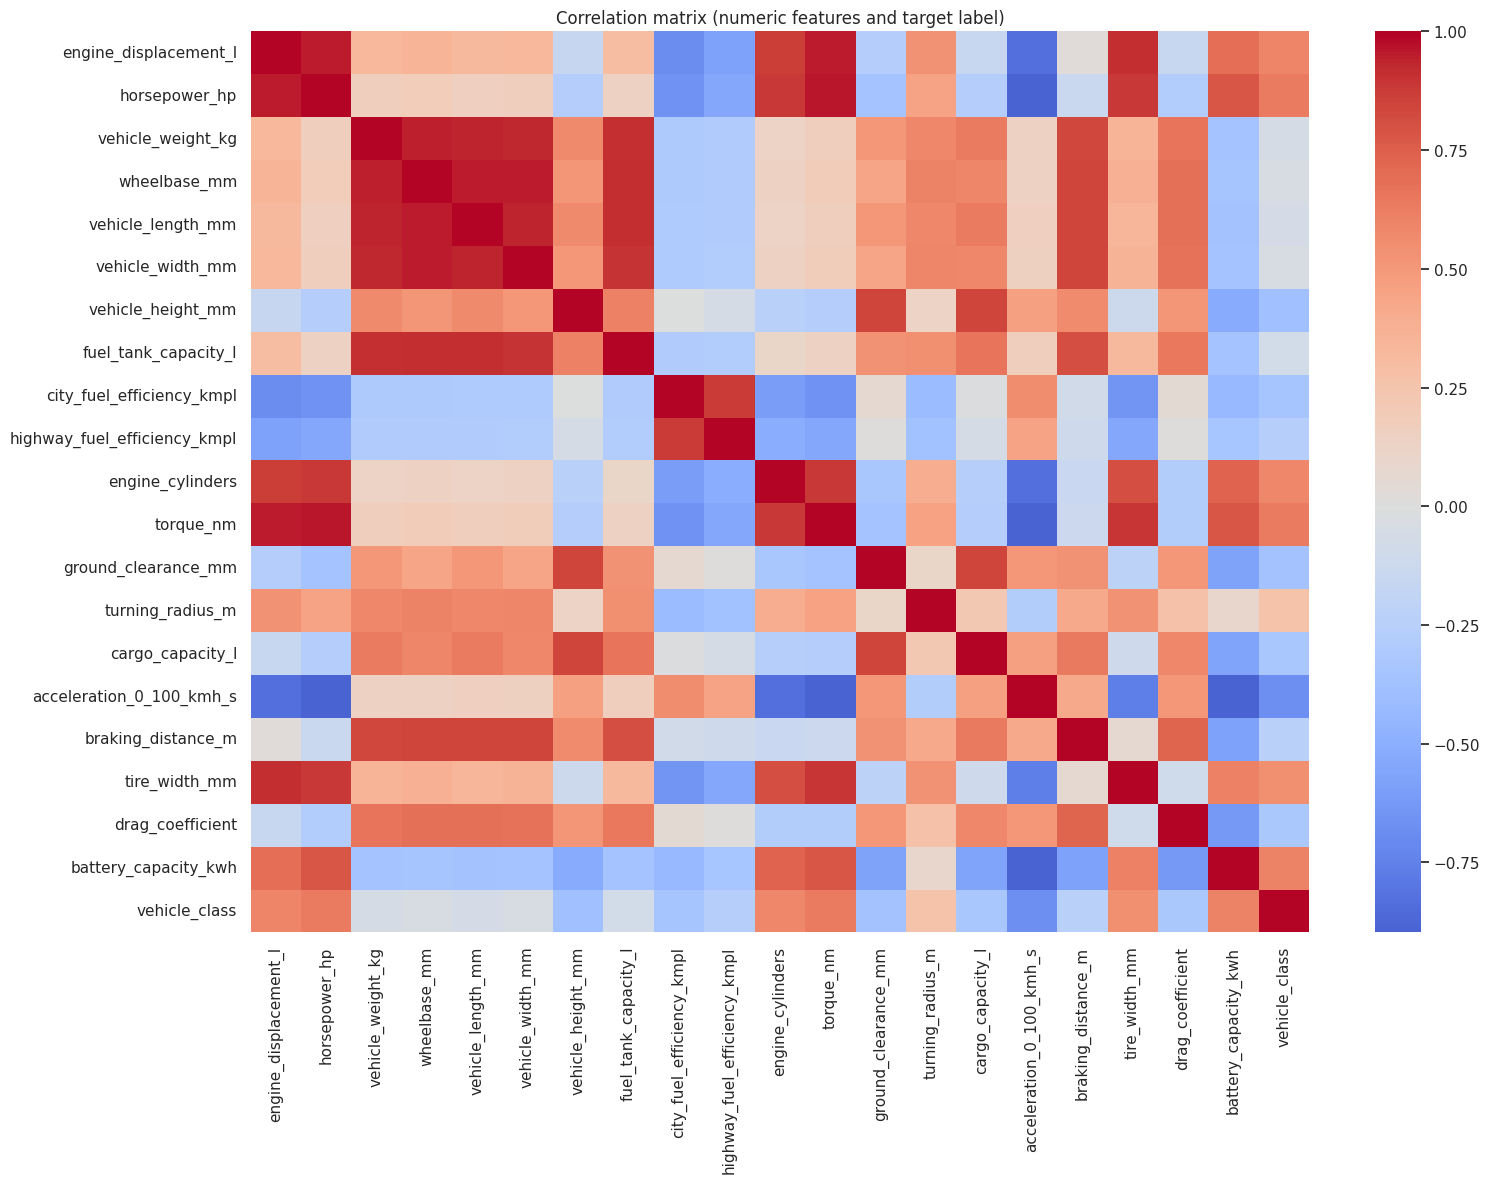

In [9]:
corr = train_df[feature_columns + [TARGET]].corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix (numeric features and target label)")
plt.tight_layout()
plt.show()

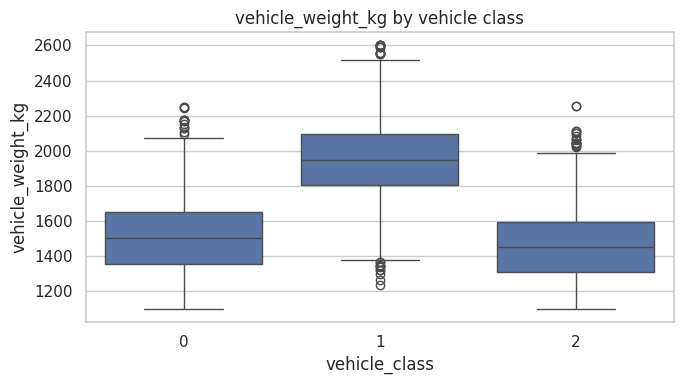

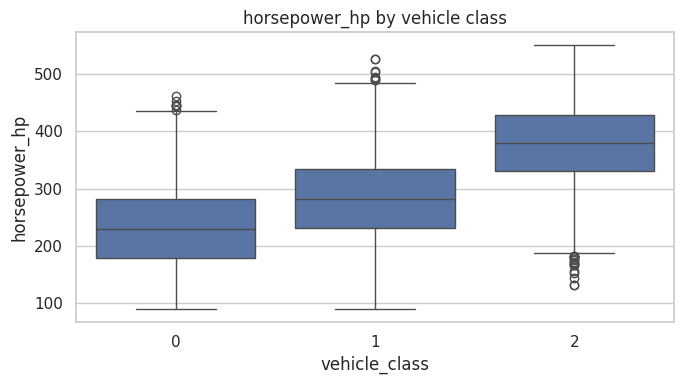

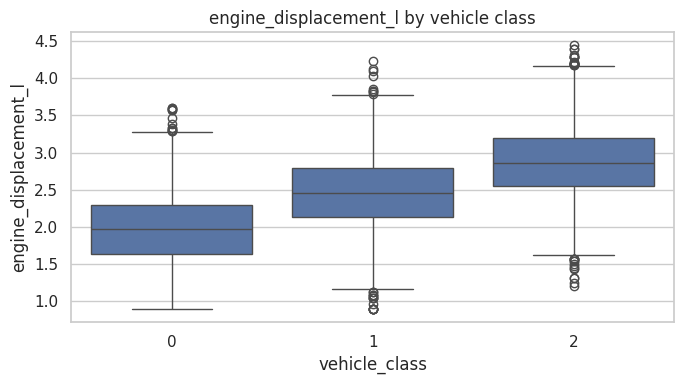

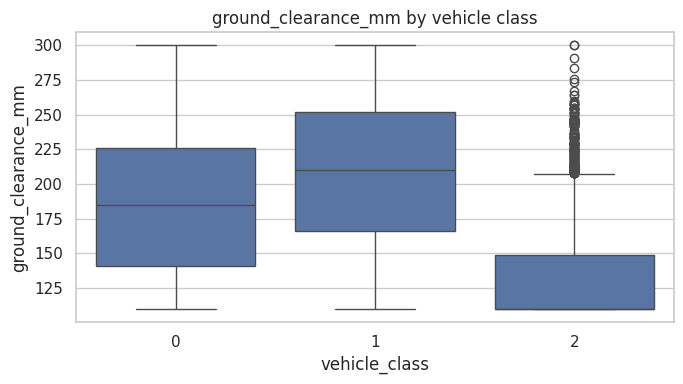

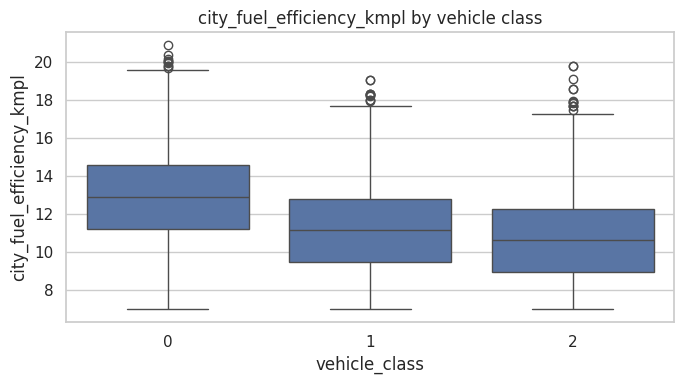

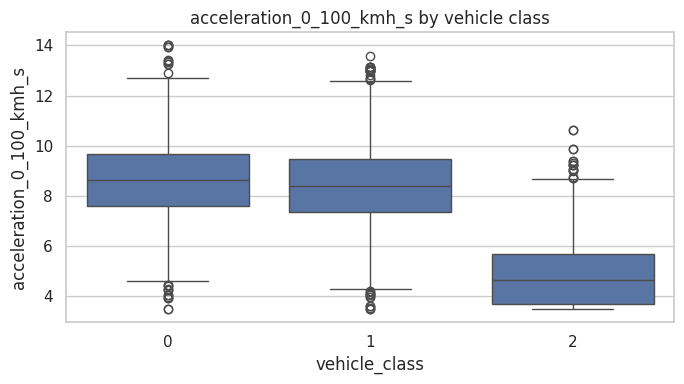

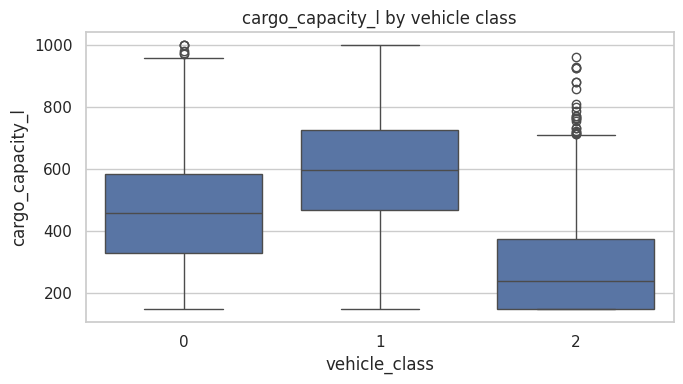

In [10]:
# Compare selected feature distributions by class.
selected_features = [
    c for c in ["vehicle_weight_kg", "horsepower_hp", "engine_displacement_l",
                "ground_clearance_mm", "city_fuel_efficiency_kmpl",
                "acceleration_0_100_kmh_s", "cargo_capacity_l"]
    if c in train_df.columns
]
for feature in selected_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=train_df, x=TARGET, y=feature)
    plt.title(f"{feature} by vehicle class")
    plt.tight_layout()
    plt.show()

In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("\nValidation class proportions:")
display(y_val.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training rows: 8000
Validation rows: 2000

Training class proportions:


,proportion
vehicle_class,
0,0.338875
1,0.332625
2,0.328500



Validation class proportions:


,proportion
vehicle_class,
0,0.3390
1,0.3325
2,0.3285


In [12]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

best_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=150,
        max_features="sqrt",
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

val_pred = best_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, val_pred):.2%}")


Validation accuracy: 92.35%


Validation accuracy: 92.3500%
Balanced accuracy: 92.3829%

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89       678
           1       0.93      0.92      0.93       665
           2       0.95      0.96      0.95       657

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000

Confusion matrix (rows = actual, columns = predicted):


,Predicted: 0,Predicted: 1,Predicted: 2
Actual: 0,606,42,30
Actual: 1,51,612,2
Actual: 2,27,1,629


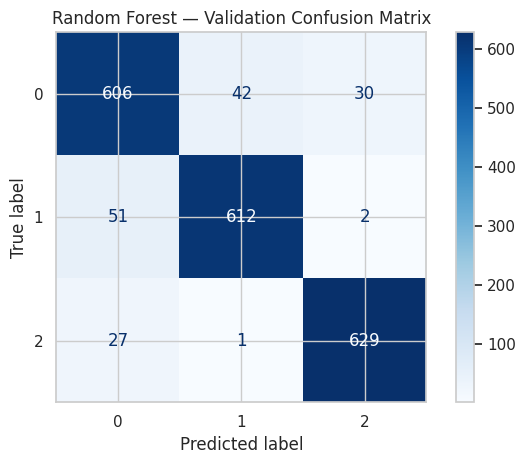

In [13]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# Predict using the already-trained model
val_pred = best_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, val_pred):.4%}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_val, val_pred):.4%}")

# Use the actual encoded class labels; no class_names variable needed
labels = sorted(y.unique())
display_names = [str(c) for c in labels]

print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    labels=labels,
    target_names=display_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_val, val_pred, labels=labels)

print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(
    cm,
    index=[f"Actual: {c}" for c in labels],
    columns=[f"Predicted: {c}" for c in labels]
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:

# Final model training and submission file creation

# Retrain the selected Random Forest model on all labeled training data
final_model = best_model
final_model.fit(X, y)

# Predict vehicle classes for the test dataset
test_predictions = final_model.predict(X_test)

print("Number of predictions:", len(test_predictions))

# Create the submission in the expected format
if sample_submission is not None:
    submission = sample_submission.copy()

    if len(submission) != len(test_predictions):
        raise ValueError("Submission rows do not match test dataset rows.")

    if TARGET in submission.columns:
        submission[TARGET] = test_predictions
    else:
        submission.iloc[:, -1] = test_predictions

else:
    submission = pd.DataFrame({
        TARGET: test_predictions
    })

    if "vehicle_id" in test_df.columns:
        submission.insert(
            0, "vehicle_id", test_df["vehicle_id"].values
        )

# Save the file to Kaggle's output directory
output_path = "/kaggle/working/random_forest_submission.csv"
submission.to_csv(output_path, index=False)

print("\nSubmission file created successfully!")
print("File:", output_path)
print("Shape:", submission.shape)
display(submission.head())


Number of predictions: 2500

Submission file created successfully!
File: /kaggle/working/random_forest_submission.csv
Shape: (2500, 2)


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1
